In [1]:
# ===== 라이브러리 import 및 버전 확인 =====
import sys
import numpy as np
import pandas as pd
import polars as pl
import sklearn
import obp

print(f"Python : {sys.version.split()[0]}")
print(f"numpy  : {np.__version__}")
print(f"pandas : {pd.__version__}")
print(f"polars : {pl.__version__}")
print(f"sklearn: {sklearn.__version__}")
print(f"obp    : {obp.__version__}")

# ===== obp 내장 소용량 데이터 로딩 테스트 =====
from obp.dataset import OpenBanditDataset

CAMPAIGN = "men"  # 캠페인 설정 (나중에 "all"로 변경)

obd_dataset = OpenBanditDataset(behavior_policy="random", campaign=CAMPAIGN)

# ===== 데이터 기본 정보 출력 =====
print(f"\n[{CAMPAIGN} / random]")
print(f"라운드 수(행 수): {obd_dataset.n_rounds}")
print(f"아이템 수      : {obd_dataset.n_actions}")
print(f"추천 슬롯 수   : {obd_dataset.len_list}")

/Users/hong/Desktop/개인 프로젝트/obd-bandit/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
INFO:obp.dataset.real:When `data_path` is not given, this class downloads the small-sized version of Open Bandit Dataset.


Python : 3.9.13
numpy  : 1.23.5
pandas : 1.5.2
polars : 1.36.1
sklearn: 1.1.3
obp    : 0.5.7

[men / random]
라운드 수(행 수): 10000
아이템 수      : 34
추천 슬롯 수   : 3


In [3]:
obd_dataset.data

,timestamp,item_id,position,click,propensity_score,user_feature_0,user_feature_1,user_feature_2,user_feature_3,user-item_affinity_0,...,user-item_affinity_24,user-item_affinity_25,user-item_affinity_26,user-item_affinity_27,user-item_affinity_28,user-item_affinity_29,user-item_affinity_30,user-item_affinity_31,user-item_affinity_32,user-item_affinity_33
0,2019-11-24 00:03:13.442536+00:00,14,3,0,0.029412,cef3390ed299c09874189c387777674a,03a5648a76832f83c859d46bc06cb64a,7bc94a2da491829b777c49c4b5e480f2,9bde591ffaab8d54c457448e4dca6f53,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2019-11-24 00:03:36.705207+00:00,10,3,0,0.029412,cef3390ed299c09874189c387777674a,03a5648a76832f83c859d46bc06cb64a,9f4e8271d3d3014af5f35124c2de5082,9bde591ffaab8d54c457448e4dca6f53,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2019-11-24 00:05:39.519963+00:00,31,1,0,0.029412,cef3390ed299c09874189c387777674a,03a5648a76832f83c859d46bc06cb64a,7bc94a2da491829b777c49c4b5e480f2,9bde591ffaab8d54c457448e4dca6f53,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2019-11-24 00:08:15.760482+00:00,12,1,0,0.029412,cef3390ed299c09874189c387777674a,03a5648a76832f83c859d46bc06cb64a,2723d2eb8bba04e0362098011fa3997b,9bde591ffaab8d54c457448e4dca6f53,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2019-11-24 00:08:21.388199+00:00,20,1,0,0.029412,cef3390ed299c09874189c387777674a,03a5648a76832f83c859d46bc06cb64a,7bc94a2da491829b777c49c4b5e480f2,c39b0c7dd5d4eb9a18e7db6ba2f258f8,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,2019-11-30 23:51:01.977491+00:00,9,2,0,0.029412,cef3390ed299c09874189c387777674a,03a5648a76832f83c859d46bc06cb64a,302deff13f835d731df1c842eed95971,9bde591ffaab8d54c457448e4dca6f53,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9996,2019-11-30 23:52:34.305870+00:00,21,3,0,0.029412,cef3390ed299c09874189c387777674a,03a5648a76832f83c859d46bc06cb64a,9b2d331c329ceb74d3dcfb48d8798c78,9bde591ffaab8d54c457448e4dca6f53,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9997,2019-11-30 23:53:47.096346+00:00,24,1,0,0.029412,cef3390ed299c09874189c387777674a,03a5648a76832f83c859d46bc06cb64a,9b2d331c329ceb74d3dcfb48d8798c78,9bde591ffaab8d54c457448e4dca6f53,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9998,2019-11-30 23:54:58.324417+00:00,13,3,0,0.029412,cef3390ed299c09874189c387777674a,2d03db5543b14483e52d761760686b64,c2e4f76cdbabecd33b8c762aeef386b3,f97571b9c14a786aab269f0b427d2a85,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# 1. EDA 및 cleansing

## 1-1. 데이터 불러오기

In [5]:
# ===== 라이브러리 import 및 설정 =====
from pathlib import Path
import polars as pl
from obp.dataset import OpenBanditDataset

CAMPAIGN = "men"            # 캠페인 설정 (나중에 "all"로 변경)
BEHAVIOR_POLICY = "random"  # 로깅 정책

# ===== obp 내장 데이터 경로 확인 =====
obd_dataset = OpenBanditDataset(behavior_policy=BEHAVIOR_POLICY, campaign=CAMPAIGN)
campaign_dir = Path(obd_dataset.data_path)

print(f"데이터 폴더: {campaign_dir}")
print("폴더 내 파일:", [file_path.name for file_path in campaign_dir.glob("*.csv")])

# ===== 원본 CSV 로딩 (로그 데이터, 아이템 피처) =====
log_df = pl.read_csv(campaign_dir / f"{CAMPAIGN}.csv")
item_df = pl.read_csv(campaign_dir / "item_context.csv")

# ===== 로그 데이터 구조 확인 =====
print(f"\n[로그 데이터] shape: {log_df.shape}")
print(log_df.schema)
print(log_df.head())

# ===== 아이템 피처 데이터 구조 확인 =====
print(f"\n[아이템 피처] shape: {item_df.shape}")
print(item_df.schema)
print(item_df.head())

INFO:obp.dataset.real:When `data_path` is not given, this class downloads the small-sized version of Open Bandit Dataset.


데이터 폴더: /Users/hong/Desktop/개인 프로젝트/obd-bandit/.venv/lib/python3.9/site-packages/obp/dataset/obd/random/men
폴더 내 파일: ['item_context.csv', 'men.csv']

[로그 데이터] shape: (10000, 44)
Schema([('', Int64), ('timestamp', String), ('item_id', Int64), ('position', Int64), ('click', Int64), ('propensity_score', Float64), ('user_feature_0', String), ('user_feature_1', String), ('user_feature_2', String), ('user_feature_3', String), ('user-item_affinity_0', Float64), ('user-item_affinity_1', Float64), ('user-item_affinity_2', Float64), ('user-item_affinity_3', Float64), ('user-item_affinity_4', Float64), ('user-item_affinity_5', Float64), ('user-item_affinity_6', Float64), ('user-item_affinity_7', Float64), ('user-item_affinity_8', Float64), ('user-item_affinity_9', Float64), ('user-item_affinity_10', Float64), ('user-item_affinity_11', Float64), ('user-item_affinity_12', Float64), ('user-item_affinity_13', Float64), ('user-item_affinity_14', Float64), ('user-item_affinity_15', Float64), ('

In [ ]:
print(log_df.columns)
log_df

# timestamp: 노출 시각
# position: 상품이 노출된 배너 위치
# click: 클릭 여부
# propensity_score: 이 아이템이 노출될 확률
# user_feature_0~3: 유저 특성
# user-item_affinity_0~33: 아이템 34개와 유저 간의 유사도?

['', 'timestamp', 'item_id', 'position', 'click', 'propensity_score', 'user_feature_0', 'user_feature_1', 'user_feature_2', 'user_feature_3', 'user-item_affinity_0', 'user-item_affinity_1', 'user-item_affinity_2', 'user-item_affinity_3', 'user-item_affinity_4', 'user-item_affinity_5', 'user-item_affinity_6', 'user-item_affinity_7', 'user-item_affinity_8', 'user-item_affinity_9', 'user-item_affinity_10', 'user-item_affinity_11', 'user-item_affinity_12', 'user-item_affinity_13', 'user-item_affinity_14', 'user-item_affinity_15', 'user-item_affinity_16', 'user-item_affinity_17', 'user-item_affinity_18', 'user-item_affinity_19', 'user-item_affinity_20', 'user-item_affinity_21', 'user-item_affinity_22', 'user-item_affinity_23', 'user-item_affinity_24', 'user-item_affinity_25', 'user-item_affinity_26', 'user-item_affinity_27', 'user-item_affinity_28', 'user-item_affinity_29', 'user-item_affinity_30', 'user-item_affinity_31', 'user-item_affinity_32', 'user-item_affinity_33']


,timestamp,item_id,position,click,propensity_score,user_feature_0,user_feature_1,user_feature_2,user_feature_3,user-item_affinity_0,user-item_affinity_1,user-item_affinity_2,user-item_affinity_3,user-item_affinity_4,user-item_affinity_5,user-item_affinity_6,user-item_affinity_7,user-item_affinity_8,user-item_affinity_9,user-item_affinity_10,user-item_affinity_11,user-item_affinity_12,user-item_affinity_13,user-item_affinity_14,user-item_affinity_15,user-item_affinity_16,user-item_affinity_17,user-item_affinity_18,user-item_affinity_19,user-item_affinity_20,user-item_affinity_21,user-item_affinity_22,user-item_affinity_23,user-item_affinity_24,user-item_affinity_25,user-item_affinity_26,user-item_affinity_27,user-item_affinity_28,user-item_affinity_29,user-item_affinity_30,user-item_affinity_31,user-item_affinity_32,user-item_affinity_33
i64,str,i64,i64,i64,f64,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0,"""2019-11-24 00:03:13.442536+00:…",14,3,0,0.029412,"""cef3390ed299c09874189c38777767…","""03a5648a76832f83c859d46bc06cb6…","""7bc94a2da491829b777c49c4b5e480…","""9bde591ffaab8d54c457448e4dca6f…",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,"""2019-11-24 00:03:36.705207+00:…",10,3,0,0.029412,"""cef3390ed299c09874189c38777767…","""03a5648a76832f83c859d46bc06cb6…","""9f4e8271d3d3014af5f35124c2de50…","""9bde591ffaab8d54c457448e4dca6f…",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,"""2019-11-24 00:05:39.519963+00:…",31,1,0,0.029412,"""cef3390ed299c09874189c38777767…","""03a5648a76832f83c859d46bc06cb6…","""7bc94a2da491829b777c49c4b5e480…","""9bde591ffaab8d54c457448e4dca6f…",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,"""2019-11-24 00:08:15.760482+00:…",12,1,0,0.029412,"""cef3390ed299c09874189c38777767…","""03a5648a76832f83c859d46bc06cb6…","""2723d2eb8bba04e0362098011fa399…","""9bde591ffaab8d54c457448e4dca6f…",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,"""2019-11-24 00:08:21.388199+00:…",20,1,0,0.029412,"""cef3390ed299c09874189c38777767…","""03a5648a76832f83c859d46bc06cb6…","""7bc94a2da491829b777c49c4b5e480…","""c39b0c7dd5d4eb9a18e7db6ba2f258…",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
9995,"""2019-11-30 23:51:01.977491+00:…",9,2,0,0.029412,"""cef3390ed299c09874189c38777767…","""03a5648a76832f83c859d46bc06cb6…","""302deff13f835d731df1c842eed959…","""9bde591ffaab8d54c457448e4dca6f…",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9996,"""2019-11-30 23:52:34.305870+00:…",21,3,0,0.029412,"""cef3390ed299c09874189c38777767…","""03a5648a76832f83c859d46bc06cb6…","""9b2d331c329ceb74d3dcfb48d8798c…","""9bde591ffaab8d54c457448e4dca6f…",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9997,"""2019-11-30 23:53:47.096346+00:…",24,1,0,0.029412,"""cef3390ed299c09874189c38777767…","""03a5648a76832f83c859d46bc06cb6…","""9b2d331c329ceb74d3dcfb48d8798c…","""9bde591ffaab8d54c457448e4dca6f…",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [10]:
print(item_df.columns)
item_df

['', 'item_id', 'item_feature_0', 'item_feature_1', 'item_feature_2', 'item_feature_3']


,item_id,item_feature_0,item_feature_1,item_feature_2,item_feature_3
i64,i64,f64,str,str,str
0,0,-0.677183,"""ceca20033d7d36b74dc683ddfb804a…","""eb6f942c01859574cb88d2e62bf843…","""795091554fd8f6b4a0ca7df81bf50a…"
1,1,-0.7203,"""270de57201b8ec18df9a72ed7ecf20…","""eb6f942c01859574cb88d2e62bf843…","""795091554fd8f6b4a0ca7df81bf50a…"
2,2,0.745662,"""270de57201b8ec18df9a72ed7ecf20…","""2ba5916b91fd2d0688459ba79f033a…","""14fb049a96497a5deef345c1c38b24…"
3,3,-0.698741,"""cb4655bc2d2e54055efefb998883d6…","""1d8ba92fbaa83078dfe330d66b81e5…","""5cc21cc265333250f10b13783ab064…"
4,4,1.651109,"""ca9488139d82dbbf68a4e71fc7fe52…","""f65e8237cca7eb6b12f4f009a28a6f…","""14fb049a96497a5deef345c1c38b24…"
…,…,…,…,…,…
29,29,-0.849649,"""dbb8044a5cc8d79d0e5c3cf996e2d0…","""5adc59d478af904390b1de5af7f33d…","""795091554fd8f6b4a0ca7df81bf50a…"
30,30,-0.914324,"""dbb8044a5cc8d79d0e5c3cf996e2d0…","""ec5fb795fb7b3a111ad15e15064875…","""795091554fd8f6b4a0ca7df81bf50a…"
31,31,-0.4616,"""0450516d22e9e70b0ee136549576d0…","""5adc59d478af904390b1de5af7f33d…","""795091554fd8f6b4a0ca7df81bf50a…"


## 1-2. cleansing

- 불필요 컬럼 삭제
- timestamp 시간 순 정렬
- 결측치 및 중복 확인
- 주요 컬럼 값 범위 확인
- propensity score 균등 여부 (=추천 정책 random인 경우)

In [11]:
# ===== 불필요 컬럼 삭제 및 timestamp 타입 변환 =====
clean_log_df = (
    log_df
    .drop("")  # 이름 없는 인덱스 컬럼 삭제
    .with_columns(
        # 예: "2019-11-24 00:03:13.442536+00:00" → datetime (UTC)
        pl.col("timestamp").str.to_datetime(format="%Y-%m-%d %H:%M:%S%.f%:z")
    )
)
clean_item_df = item_df.drop("")

# ===== 시간순 정렬 여부 및 수집 기간 확인 =====
print("[시간 정렬]")
print(f"시간순 정렬 여부: {clean_log_df['timestamp'].is_sorted()}")
print(f"수집 기간: {clean_log_df['timestamp'].min()} ~ {clean_log_df['timestamp'].max()}")

# ===== 결측치 및 중복 행 확인 =====
null_count_df = (
    clean_log_df.null_count()
    .transpose(include_header=True, header_name="column", column_names=["null_count"])
    .filter(pl.col("null_count") > 0)
)
print("\n[품질 점검]")
print(f"결측치 있는 컬럼 수: {null_count_df.height}")
if null_count_df.height > 0:
    print(null_count_df)
print(f"중복 행 수: {clean_log_df.is_duplicated().sum()}")

# ===== 주요 컬럼 값 범위 확인 =====
print("\n[값 범위]")
print(f"item_id : {clean_log_df['item_id'].min()} ~ {clean_log_df['item_id'].max()}, "
      f"고유값 {clean_log_df['item_id'].n_unique()}개")
print(f"position: {sorted(clean_log_df['position'].unique().to_list())}")
print(f"click   : {sorted(clean_log_df['click'].unique().to_list())}")

# ===== propensity score 균등 여부 확인 =====
n_items = clean_item_df.height
print("\n[propensity score]")
print(f"이론값 1/{n_items} = {1 / n_items:.6f}")
print(clean_log_df.select(
    pl.col("propensity_score").min().alias("min"),
    pl.col("propensity_score").max().alias("max"),
    pl.col("propensity_score").mean().alias("mean"),
    pl.col("propensity_score").n_unique().alias("n_unique"),
))

[시간 정렬]
시간순 정렬 여부: True
수집 기간: 2019-11-24 00:03:13.442536+00:00 ~ 2019-11-30 23:58:59.642633+00:00

[품질 점검]
결측치 있는 컬럼 수: 0
중복 행 수: 0

[값 범위]
item_id : 0 ~ 33, 고유값 34개
position: [1, 2, 3]
click   : [0, 1]

[propensity score]
이론값 1/34 = 0.029412
shape: (1, 4)
┌──────────┬──────────┬──────────┬──────────┐
│ min      ┆ max      ┆ mean     ┆ n_unique │
│ ---      ┆ ---      ┆ ---      ┆ ---      │
│ f64      ┆ f64      ┆ f64      ┆ u32      │
╞══════════╪══════════╪══════════╪══════════╡
│ 0.029412 ┆ 0.029412 ┆ 0.029412 ┆ 1        │
└──────────┴──────────┴──────────┴──────────┘


## 1-3. eda - 클릭률 확인

- 전체 -> position별 -> item별

- 소용량 샘플 데이터에서 이거 보는 건 의미가 없음

[전체]
노출 10,000 / 클릭 46 / 클릭률 0.4600%

[슬롯별]
shape: (3, 4)
┌──────────┬─────────────┬────────┬──────────┐
│ position ┆ impressions ┆ clicks ┆ ctr      │
│ ---      ┆ ---         ┆ ---    ┆ ---      │
│ i64      ┆ u32         ┆ i64    ┆ f64      │
╞══════════╪═════════════╪════════╪══════════╡
│ 1        ┆ 3284        ┆ 10     ┆ 0.003045 │
│ 2        ┆ 3388        ┆ 22     ┆ 0.006494 │
│ 3        ┆ 3328        ┆ 14     ┆ 0.004207 │
└──────────┴─────────────┴────────┴──────────┘

[아이템별 요약]
shape: (1, 7)
┌─────────────────┬────────────────┬────────────┬────────────┬────────────────┬─────────┬──────────┐
│ impressions_min ┆ impressions_ma ┆ clicks_min ┆ clicks_max ┆ zero_click_ite ┆ ctr_min ┆ ctr_max  │
│ ---             ┆ x              ┆ ---        ┆ ---        ┆ ms             ┆ ---     ┆ ---      │
│ u32             ┆ ---            ┆ i64        ┆ i64        ┆ ---            ┆ f64     ┆ f64      │
│                 ┆ u32            ┆            ┆            ┆ u32            ┆         ┆ 

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


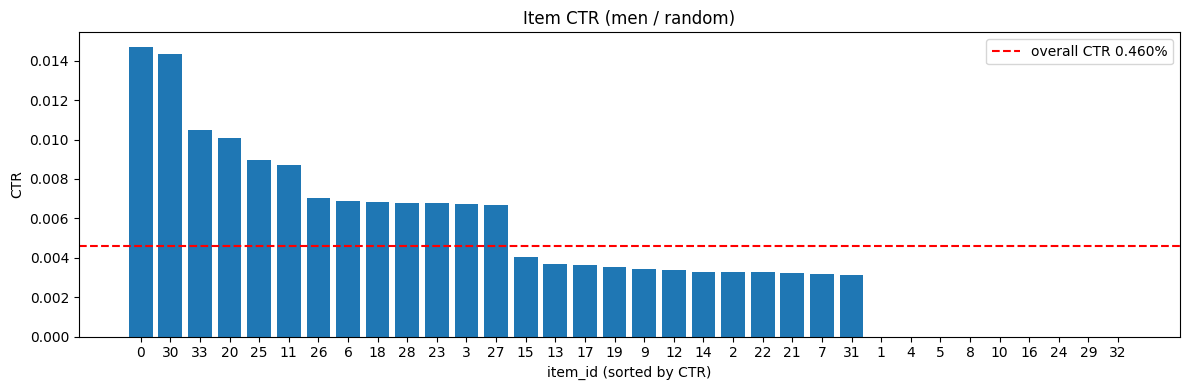

In [12]:
import matplotlib.pyplot as plt

# ===== 공통: 그룹별 노출 수, 클릭 수, 클릭률 집계 함수 =====
def summarize_ctr(source_df: pl.DataFrame, group_cols: list) -> pl.DataFrame:
    return (
        source_df
        .group_by(group_cols)
        .agg(
            pl.len().alias("impressions"),
            pl.col("click").sum().alias("clicks"),
            pl.col("click").mean().alias("ctr"),
        )
        .sort(group_cols)
    )

# ===== 1. 전체 클릭률 =====
total_impressions = clean_log_df.height
total_clicks = clean_log_df["click"].sum()
overall_ctr = total_clicks / total_impressions
print("[전체]")
print(f"노출 {total_impressions:,} / 클릭 {total_clicks:,} / 클릭률 {overall_ctr:.4%}")

# ===== 2. 슬롯(position)별 클릭률 =====
position_ctr_df = summarize_ctr(clean_log_df, ["position"])
print("\n[슬롯별]")
print(position_ctr_df)

# ===== 3. 아이템별 클릭률 =====
item_ctr_df = summarize_ctr(clean_log_df, ["item_id"])
print("\n[아이템별 요약]")
print(item_ctr_df.select(
    pl.col("impressions").min().alias("impressions_min"),
    pl.col("impressions").max().alias("impressions_max"),
    pl.col("clicks").min().alias("clicks_min"),
    pl.col("clicks").max().alias("clicks_max"),
    (pl.col("clicks") == 0).sum().alias("zero_click_items"),
    pl.col("ctr").min().alias("ctr_min"),
    pl.col("ctr").max().alias("ctr_max"),
))

# ===== 아이템별 클릭률 시각화 (전체 평균선 포함) =====
sorted_item_ctr_df = item_ctr_df.sort("ctr", descending=True)
fig, axis = plt.subplots(figsize=(12, 4))
axis.bar(sorted_item_ctr_df["item_id"].cast(pl.String).to_list(),
         sorted_item_ctr_df["ctr"].to_list())
axis.axhline(overall_ctr, color="red", linestyle="--", label=f"overall CTR {overall_ctr:.3%}")
axis.set_xlabel("item_id (sorted by CTR)")
axis.set_ylabel("CTR")
axis.set_title(f"Item CTR ({CAMPAIGN} / {BEHAVIOR_POLICY})")
axis.legend()
plt.tight_layout()
plt.show()

## 1-4. eda - 사용자 피처

In [15]:
# ===== 사용자 피처: 범주 수 및 범주별 노출 분포 =====
user_feature_cols = [f"user_feature_{feature_idx}" for feature_idx in range(4)]

print("[사용자 피처 범주 수]")
for feature_col in user_feature_cols:
    print(f"{feature_col}: {clean_log_df[feature_col].n_unique()}개")

for feature_col in user_feature_cols:
    category_count_df = (
        clean_log_df[feature_col]
        .value_counts(sort=True)
        .with_columns((pl.col("count") / clean_log_df.height).alias("share"))
    )
    print(f"\n[{feature_col} 범주별 분포]")
    print(category_count_df)

# ===== 사용자-아이템 친밀도: 값 범위 및 0이 아닌 비율 =====
affinity_cols = [col for col in clean_log_df.columns if col.startswith("user-item_affinity")]
affinity_values = clean_log_df.select(affinity_cols).to_numpy()

print("\n[사용자-아이템 친밀도]")
print(f"컬럼 수: {len(affinity_cols)}")
print(f"값 범위: {affinity_values.min()} ~ {affinity_values.max()}")
print(f"0이 아닌 값 비율: {(affinity_values != 0).mean():.2%}")
print(f"친밀도가 하나라도 있는 행 비율: {(affinity_values != 0).any(axis=1).mean():.2%}")

# ===== 아이템 피처: 범주 수 =====
print("\n[아이템 피처 범주 수]")
for feature_col in ["item_feature_1", "item_feature_2", "item_feature_3"]: # item_feature_4는 수치형
    print(f"{feature_col}: {clean_item_df[feature_col].n_unique()}개")

[사용자 피처 범주 수]
user_feature_0: 3개
user_feature_1: 5개
user_feature_2: 9개
user_feature_3: 8개

[user_feature_0 범주별 분포]
shape: (3, 3)
┌─────────────────────────────────┬───────┬────────┐
│ user_feature_0                  ┆ count ┆ share  │
│ ---                             ┆ ---   ┆ ---    │
│ str                             ┆ u32   ┆ f64    │
╞═════════════════════════════════╪═══════╪════════╡
│ cef3390ed299c09874189c38777767… ┆ 8651  ┆ 0.8651 │
│ 81ce123cbb5bd8ce818f60fb3586bb… ┆ 1316  ┆ 0.1316 │
│ 4ae385d792f81dde128124a925a830… ┆ 33    ┆ 0.0033 │
└─────────────────────────────────┴───────┴────────┘

[user_feature_1 범주별 분포]
shape: (5, 3)
┌─────────────────────────────────┬───────┬────────┐
│ user_feature_1                  ┆ count ┆ share  │
│ ---                             ┆ ---   ┆ ---    │
│ str                             ┆ u32   ┆ f64    │
╞═════════════════════════════════╪═══════╪════════╡
│ 03a5648a76832f83c859d46bc06cb6… ┆ 7891  ┆ 0.7891 │
│ 2d03db5543b14483e52d761760686b… ┆ 1

## 1-5. eda - 원본 데이터, 소용량 데이터 매칭 확인

In [16]:
# ===== 전체 버전 경로 설정 (노트북이 notebooks/ 폴더에 있다고 가정) =====
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
full_campaign_dir = DATA_DIR / BEHAVIOR_POLICY / CAMPAIGN

# ===== 전체 버전 로딩 및 소용량과 동일한 정리 적용 =====
full_log_df = (
    pl.read_csv(full_campaign_dir / f"{CAMPAIGN}.csv")
    .drop("")
    .with_columns(pl.col("timestamp").str.to_datetime(format="%Y-%m-%d %H:%M:%S%.f%:z"))
)
full_item_df = pl.read_csv(full_campaign_dir / "item_context.csv").drop("")

# ===== 1. 컬럼 구성 및 타입 비교 =====
print("[컬럼 및 타입]")
print(f"컬럼 이름/순서 동일: {full_log_df.columns == clean_log_df.columns}")
print(f"컬럼 타입 동일     : {full_log_df.schema == clean_log_df.schema}")
print(f"아이템 피처 동일   : {full_item_df.equals(clean_item_df)}")

# ===== 2. 기본 정보 비교 =====
print("\n[기본 정보]  소용량 → 전체")
print(f"행 수      : {clean_log_df.height:,} → {full_log_df.height:,}")
print(f"아이템 수  : {clean_log_df['item_id'].n_unique()} → {full_log_df['item_id'].n_unique()}")
print(f"position   : {sorted(full_log_df['position'].unique().to_list())}")
print(f"click      : {sorted(full_log_df['click'].unique().to_list())}")
print(f"propensity : {full_log_df['propensity_score'].unique().to_list()}")
print(f"수집 기간  : {full_log_df['timestamp'].min()} ~ {full_log_df['timestamp'].max()}")
print(f"시간순 정렬: {full_log_df['timestamp'].is_sorted()}")

# ===== 3. 품질 점검 =====
print("\n[품질 점검]")
print(f"결측치 총합: {full_log_df.null_count().sum_horizontal().item()}")
print(f"중복 행 수 : {full_log_df.is_duplicated().sum()}")

# ===== 4. 사용자 피처 범주 비교 (소용량에 없던 범주 확인) =====
print("\n[사용자 피처 범주 수]  소용량 → 전체 (전체에만 있는 범주 수)")
for feature_col in user_feature_cols:
    small_categories = set(clean_log_df[feature_col].unique().to_list())
    full_categories = set(full_log_df[feature_col].unique().to_list())
    print(f"{feature_col}: {len(small_categories)} → {len(full_categories)} "
          f"(신규 {len(full_categories - small_categories)}개)")

# ===== 5. BTS 로그: 전체 로딩 없이 컬럼 구성과 클릭률만 확인 =====
bts_lazy_df = pl.scan_csv(DATA_DIR / "bts" / CAMPAIGN / f"{CAMPAIGN}.csv")
bts_summary_df = bts_lazy_df.select(
    pl.len().alias("impressions"),
    pl.col("click").sum().alias("clicks"),
    pl.col("click").mean().alias("ctr"),
).collect()

print("\n[BTS 로그]")
print(f"컬럼 이름 동일(정리 전 기준): {bts_lazy_df.collect_schema().names() == log_df.columns}")
print(bts_summary_df)

[컬럼 및 타입]
컬럼 이름/순서 동일: True
컬럼 타입 동일     : True
아이템 피처 동일   : False

[기본 정보]  소용량 → 전체
행 수      : 10,000 → 452,949
아이템 수  : 34 → 34
position   : [1, 2, 3]
click      : [0, 1]
propensity : [0.029411764705882353]
수집 기간  : 2019-11-24 00:00:03.800821+00:00 ~ 2019-11-30 23:59:58.340081+00:00
시간순 정렬: True

[품질 점검]
결측치 총합: 0
중복 행 수 : 151

[사용자 피처 범주 수]  소용량 → 전체 (전체에만 있는 범주 수)
user_feature_0: 3 → 4 (신규 1개)
user_feature_1: 5 → 6 (신규 1개)
user_feature_2: 9 → 11 (신규 2개)
user_feature_3: 8 → 10 (신규 2개)

[BTS 로그]
컬럼 이름 동일(정리 전 기준): True
shape: (1, 3)
┌─────────────┬────────┬──────────┐
│ impressions ┆ clicks ┆ ctr      │
│ ---         ┆ ---    ┆ ---      │
│ u32         ┆ i64    ┆ f64      │
╞═════════════╪════════╪══════════╡
│ 4077727     ┆ 27495  ┆ 0.006743 │
└─────────────┴────────┴──────────┘
